## Деференциално и интегрално смятане: Охлаждане и Термодинамика
Охлаждането отнема между 80% и 85% от производственият цикъл. Изчисляването на времето за охлаждане е важно за продуктивността.
### Математически концепции
* Диференциални уравнения - Закон на Нютон за охлаждането
Законът на Нютон за охлаждането гласи, че скоростта на изменение на температурата на едно тяло е правопропорционална на разликата между температурата на тялото и температурата на околната среда.
$$\frac{dT}{dt} = -k(T - T_a)$$
При технологията щприцоване на пластмаса (*injection moulding*), прилагането на за закона на Нютон за охлаждане в този процес обаче има специфични инженерни особености. Законът служи като **фундаментална основа за изчисляване на топлообмена**, но реалният процес е много по-сложен поради физичните свойства на пластмасите.
Поради лошата си топлопроводимост, външният слой, който докосва металната матрица, изстива мигновенно, но вътрешността на детайла остава гореща за по-дълго време.
Когато пластмасата изстива, тя се свива. Това свиване я отделя леко от матрицата и се образува микроскопичен въздушен слой. Въздухът също е лош проводник на топлина. Поради това константата на охлаждане (**k**  от закона на Нютон) рязко намалява, което забавя охлаждането.
* Логаритмични функции
### Инженерна формула за охлаждане при щприцоване на пластмаса:
В тази формула, законът на Нютон за охлаждане се интегрира в по-сложни уравнения за топлопроводимост на Фурие. За изчисляване на времето на охлаждане   $t_{\text{c}}$ се използва следната теоритична формула, която съдържа логаритмичната зависимост от закона на Нютон:
$$t_c = \frac{h^2}{\pi^2 \times \alpha} \ln\left(\frac{4}{\pi} \times \frac{T_m - T_w}{T_e - T_w} \right)$$

* $h$  - максималната дебелина на стената на детайла($mm$)
* $\alpha$  - термичната дефузия на материала ($mm^2/s$)
* $T_m$  - температура на разстопената пластмаса (°C)
* $T_w$  - температура на стената на матрицата (°C)
* $T_e$  - температура на детайла при изваждане (°C)


In [7]:
import sympy as sp
from IPython.display import display, Math
t, s, T_m, T_w, T_e, alpha, B = sp.symbols('t s T_m T_w T_e alpha B')
T_t = T_w + (4 / sp.pi) * (T_m - T_w) * sp.exp(-B * t)
dT_dt = sp.diff(T_t, t)
B_exact = sp.pi**2 * alpha / s**2
dT_dt_full = dT_dt.subs(B, B_exact)
print("Генериране формули от Python кода:")
print("-"*40)
display(Math(r"\text{1. Основна температурана функция: } T{t} =  "+sp.latex(T_t)))
display(Math(r"\text{2. Диференциално смятане (Първа производна): } \frac{dT}{dt} = " + sp.latex(dT_dt_full)))
t_e = sp.symbols('t_e')
integral_T = sp.integrate(T_t.subs(B, B_exact), (t, 0, t_e))
T_average = (1 / t_e) * integral_T
display(Math(r"\text{3. Интегрално смятане (Средна температура): } \bar{T} = " + sp.latex(T_average.simplify())))

Генериране формули от Python кода:
----------------------------------------


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [2]:
import sympy as sp
from IPython.display import display, Math

# 1. Дефиниране на математическите символи
t, T_w, T_m, alpha, s = sp.symbols('t T_w T_m alpha s')

# Вашите специфични стойности
s_val = 0.00147    # 1.47 мм в метри
T_m_val = 235.0    # Температура на стопилката (°C)
T_w_val = 30.0     # Температура на матрицата (°C)
T_e_val = 85.0     # Температура на изваждане (°C)
alpha_val = 8.5e-8   # Коефициент за ABS пластмаса

# 2. Създаване на формулата
T_t = T_w + (4 / sp.pi) * (T_m - T_w) * sp.exp(- (sp.pi**2 * alpha * t) / (s**2))

# 3. Заместване на вашите конкретни стойности във формулата
T_t_specific = T_t.subs({T_m: T_m_val, T_w: T_w_val, s: s_val, alpha: alpha_val})

# Показване на формулата в красив вид
print("Формулата е записана в паметта на Jupyter за Клетка 2:")
display(Math(r"T(t) = " + sp.latex(T_t_specific.evalf(4))))


Формулата е записана в паметта на Jupyter за Клетка 2:


<IPython.core.display.Math object>

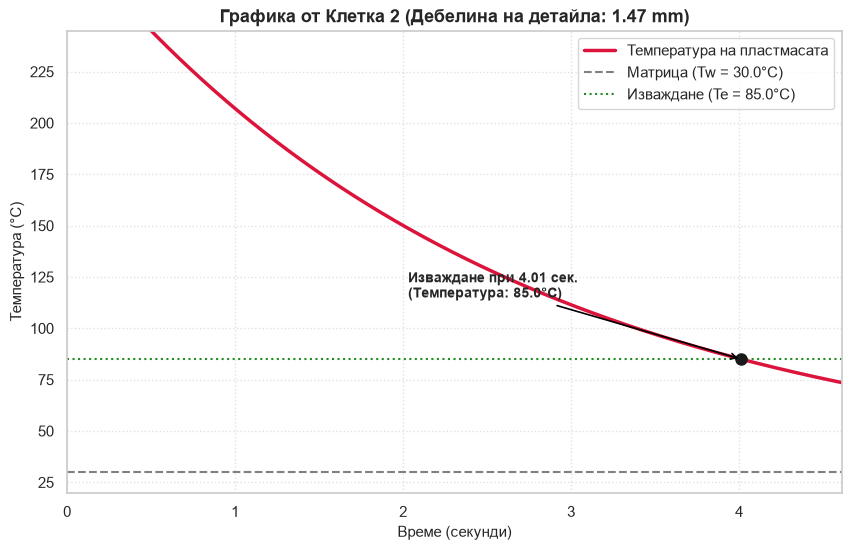

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Използваме директно T_t_specific от предната клетка и я превръщаме в Python функция
T_func = sp.lambdify(t, T_t_specific, 'numpy')

# 2. Математическо изчисляване на точното време за охлаждане до 45°C
t_ejection = (s_val**2 / (np.pi**2 * alpha_val)) * np.log((4 / np.pi) * ((T_m_val - T_w_val) / (T_e_val - T_w_val)))

# 3. Генериране на времеви стъпки за графиката
t_vals = np.linspace(0, t_ejection * 1.15, 1000)
T_vals = T_func(t_vals)

# 4. Чертане на графиката по Вашите данни
plt.figure(figsize=(10, 6))
plt.plot(t_vals, T_vals, color='crimson', linewidth=2.5, label='Температура на пластмасата')

# Помощни линии за Вашите температури
plt.axhline(y=T_w_val, color='gray', linestyle='--', label=f'Матрица (Tw = {T_w_val}°C)')
plt.axhline(y=T_e_val, color='forestgreen', linestyle=':', label=f'Изваждане (Te = {T_e_val}°C)')

# Отбелязване на точката на изваждане
plt.plot(t_ejection, T_e_val, 'ko', markersize=8)
plt.annotate(f' Изваждане при {t_ejection:.2f} сек.\n (Температура: {T_e_val}°C)',
             xy=(t_ejection, T_e_val),
             xytext=(t_ejection * 0.5, T_e_val + 30),
             arrowprops=dict(arrowstyle="->", color='black', linewidth=1.2),
             fontsize=10, fontweight='bold')

plt.title(f'Графика от Клетка 2 (Дебелина на детайла: {s_val*1000:.2f} mm)', fontsize=13, fontweight='bold')
plt.xlabel('Време (секунди)', fontsize=11)
plt.ylabel('Температура (°C)', fontsize=11)
plt.xlim(0, t_vals.max())
plt.ylim(T_w_val - 10, T_m_val + 10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)

plt.show()


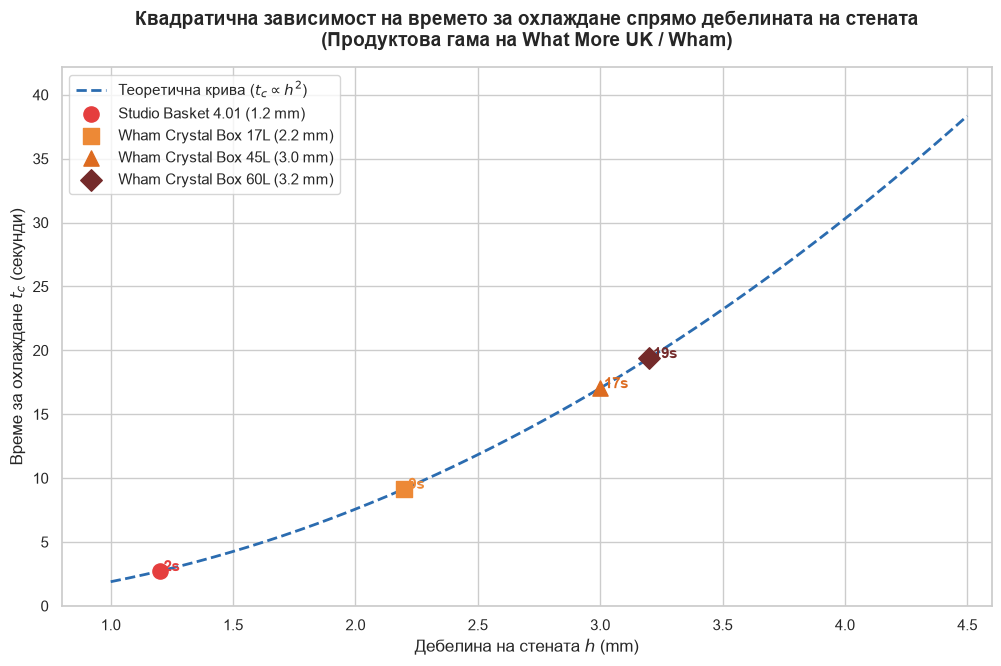

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Задаване на стил на графиката
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# 2. Дефиниране на математическата функция за охлаждане (Закон на Фурие)
# Използвам фиксирани средни температури за Полипропилен (PP)
T_m = 230  # Температура на стопилката (°C)
T_w = 30   # Температура на матрицата (°C)
T_e = 85   # Температура на изваждане (°C)
alpha = 0.082  # Термична дифузия (mm²/s)

# Изчисляване на термодинамичната константа
log_part = np.log((4 / np.pi) * ((T_m - T_w) / (T_e - T_w)))

# Генерираме непрекъснат масив от дебелини от 1.0 mm до 4.5 mm
h_line = np.linspace(1.0, 4.5, 200)
t_cooling_line = (h_line**2 / (np.pi**2 * alpha)) * log_part

# 3. Начертаване на теоретичната параболична крива
plt.plot(h_line, t_cooling_line, color='#2b6cb0', linestyle='--', linewidth=2, label=r'Теоретична крива ($t_c \propto h^2$)')

# 4. Поставяне на реални точки от гамата на Wham за контраст
# Избираме 4 характерни продукта от твоята таблица с различни дебелини
wham_examples = {
    "Studio Basket 4.01": (1.2, (1.2**2 / (np.pi**2 * alpha)) * log_part, '#e53e3e', 'o'),
    "Wham Crystal Box 17L": (2.2, (2.2**2 / (np.pi**2 * alpha)) * log_part, '#ed8936', 's'),
    "Wham Crystal Box 45L": (3.0, (3.0**2 / (np.pi**2 * alpha)) * log_part, '#dd6b20', '^'),
    "Wham Crystal Box 60L": (3.2, (3.2**2 / (np.pi**2 * alpha)) * log_part, '#742a2a', 'D')
}

# Поставяме точките върху графиката
for name, (h_val, t_val, color, marker) in wham_examples.items():
    plt.scatter(h_val, t_val, color=color, s=120, marker=marker, zorder=5, label=f"{name} ({h_val} mm)")
    # Добавяне на текстов етикет до всяка точка
    plt.annotate(f" {int(t_val)}s", (h_val, t_val), fontsize=11, fontweight='bold', color=color)

# 5. Оформяне на графиката (Заглавия и оси)
plt.title("Квадратична зависимост на времето за охлаждане спрямо дебелината на стената\n(Продуктова гама на What More UK / Wham)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Дебелина на стената $h$ (mm)", fontsize=12)
plt.ylabel("Време за охлаждане $t_c$ (секунди)", fontsize=12)
plt.xlim(0.8, 4.6)
plt.ylim(0, max(t_cooling_line) * 1.1)
plt.legend(loc="upper left", fontsize=11)

# Показване на графиката в Jupyter
plt.show()